<a href="https://colab.research.google.com/github/misbakhulfajar27-killertheriper/Tugas_2/blob/main/Tugas2_misbakhul_Fajar_047996694.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**<center>$\color{green}{\text{TUGAS 2 : KLASIFIKASI}}$</center>**

> MISBAKHUL FAJAR (047996694)



---


<p>
Universitas Terbuka adalah sebuah perguruan tinggi terbuka yang memberikan kesempatan bagi putra putri bangsa untuk menimba ilmu dan pengetahuan. UT memiliki mahasiswa dengan latar belakang yang beragam. Mahasiswanya tidak terbatas pada lulusan baru dari sma/smu/smk sederajat. Beberapa diantaranya bahkan telah/sedang bekerja. Kondisi tersebut memberikan kesulitan bagi pihak kampus dalam menerapkan strategi untuk membantu mahasiswa berhasil melewati masa kuliah dan lulus tepat waktu.
</p>

<p>
Sebagai seorang Machine Learning engineer, kamu diminta untuk membuat model yang mampu mendeteksi secara dini tigkat resiko kegagalan seorang mahasiswa. Dengan harapan jika sistem mampu memberikan informasi yang valid, maka bagian wali akademik dapat memberikan konseling yang tepat. Untuk melaksanakan tugasmu ini, kamu diberikan data yang bersumber dari dua periode penerimaan.
</p>


##Task 1
Mulailah memuat semua data yang ada ke sistem.

In [14]:
# Import library yang dipakai
import pandas as pd                # mengolah tabel data
import numpy as np                 # perhitungan angka
import matplotlib.pyplot as plt    # membuat grafik
import seaborn as sns              # grafik yang lebih rapi

# 1) Muat data dari kedua sumber
df1 = pd.read_csv("Data Siswa Periode 1.csv")   # data periode 1
df2 = pd.read_csv("Data Siswa Periode 2.csv")   # data periode 2
print("Ukuran df1:", df1.shape)                 # (jumlah baris, jumlah kolom)
print("Ukuran df2:", df2.shape)

# 2) Lihat atribut (nama kolom) dari kedua data
print(df1.columns.tolist())
print(df2.columns.tolist())

# Tambahan: tampilkan 5 baris awal dan tipe data tiap kolom
df1.head()
df1.info()

Ukuran df1: (1827, 21)
Ukuran df2: (1730, 21)
['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Reguler/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']
['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Siang/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Umur saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------        

##Task 2
Datanya sudah termuat, fitur nya hampir semuanya sama, tetapi ada yang berbeda sehingga perlu dipetakan

In [15]:
# 1) Mengidentifikasi fitur serupa, lalu menamai ulang fitur tersebut
# Usia dan Kelas memiliki arti sama di kedua data, tetapi namanya berbeda

# Mengganti nama kolom pada data periode 1
df1 = df1.rename(columns={"Usia saat mendaftar": "Usia",
                          "Kelas Reguler/Malam": "Kelas"})

# Mengganti nama kolom pada data periode 2
df2 = df2.rename(columns={"Umur saat mendaftar": "Usia",
                          "Kelas Siang/Malam": "Kelas"})

# Memeriksa apakah nama kolom kedua data sudah sama
print("Nama kolom sama?", set(df1.columns) == set(df2.columns))

Nama kolom sama? True


##Task 3
Butuh penyatuan data, tapi ternyata ada kodefikasi atribut fitur yang berbeda, harus di samakan

In [16]:
# 1) Menyamakan kodefikasi atribut

# Membandingkan isi kolom teks di kedua data, lalu menampilkan kolom yang isinya berbeda
for k in df1.select_dtypes(include="object").columns:
    if set(df1[k].dropna()) != set(df2[k].dropna()):
        print(k)
        print("   Periode 1:", df1[k].dropna().unique())
        print("   Periode 2:", df2[k].dropna().unique())

# Mengganti kode periode 1 supaya sama dengan periode 2
df1["Jenis Kelamin"] = df1["Jenis Kelamin"].replace({"Wanita": "Perempuan", "Pria": "Laki-laki"})
df1["Kelas"] = df1["Kelas"].replace({"Reguler": "Siang"})

# Memeriksa ulang hasil penyamaan
print(df1["Jenis Kelamin"].unique())
print(df1["Kelas"].unique())

# 2) Menyatukan data
df = pd.concat([df1, df2], ignore_index=True)   # menumpuk df2 di bawah df1
print("Ukuran data gabungan:", df.shape)
df.head()                                       # menampilkan 5 baris awal


Kelas
   Periode 1: ['Reguler' 'Malam']
   Periode 2: ['Siang' 'Malam']
Jenis Kelamin
   Periode 1: ['Pria' 'Wanita']
   Periode 2: ['Laki-laki' 'Perempuan']
['Laki-laki' 'Perempuan']
['Siang' 'Malam' nan]
Ukuran data gabungan: (3557, 21)


,ID,Status Pernikahan,Program Studi,Kelas,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,...,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia,IP Semester 1,IP Semester 2,Target
0,2,Belum Menikah,Teknik Industri,Siang,SMA/Sederajat,66.55,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Lainnya,...,53.00,Ya,Tidak,Sudah,Laki-laki,Tidak,21,2.48,2.52,Lulus Tepat Waktu
1,3,Belum Menikah,Jurnalistik,Siang,SMA/Sederajat,63.50,Pulau Jawa,SMA/Sederajat,Lebih dari S1,Pegawai Swasta,...,58.25,Tidak,Tidak,Sudah,Perempuan,Ya,19,2.86,2.63,Lulus Tepat Waktu
2,4,Belum Menikah,Pertanian,Siang,SMA/Sederajat,62.50,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Wiraswasta,...,60.75,Ya,Tidak,Sudah,Laki-laki,Tidak,18,2.20,2.07,Lulus Tidak Tepat Waktu
3,5,Belum Menikah,Teknik Mesin,Siang,Perguruan Tinggi,75.00,Pulau Jawa,Lebih dari S1,Lebih dari S1,Pegawai Swasta,...,75.00,Tidak,Tidak,Sudah,Perempuan,Tidak,20,2.60,2.40,Lulus Tidak Tepat Waktu
4,10,Belum Menikah,Perbankan,Siang,SMA/Sederajat,65.00,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Negri,...,64.55,Ya,Tidak,Sudah,Perempuan,Tidak,18,2.61,2.72,Lulus Tepat Waktu


##Task 4
Sekarang kita lakukan analisis atribut untuk setiap fitur nya, mulai dengan penanganan missing/null value

In [17]:
# 1) Mengidentifikasi dan menangani missing/null value

# (a) Memeriksa dan menghapus baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Ukuran data setelah hapus duplikat:", df.shape)

# (b) Memeriksa jumlah sel kosong tiap kolom
print(df.isnull().sum())

# Mengisi sel kosong dengan modus (nilai yang paling sering muncul), karena kolomnya berupa teks
df["Kelas"] = df["Kelas"].fillna(df["Kelas"].mode()[0])
df["Daerah Asal"] = df["Daerah Asal"].fillna(df["Daerah Asal"].mode()[0])

# (c) Memeriksa usia negatif (tidak mungkin terjadi, kemungkinan salah input)
print("Jumlah usia negatif:", (df["Usia"] < 0).sum())

# Mengganti usia negatif dengan median usia
df.loc[df["Usia"] < 0, "Usia"] = df["Usia"].median()

# Memeriksa ulang hasilnya
print("Sisa sel kosong:", df.isnull().sum().sum())
print("Usia minimum:", df["Usia"].min())

Jumlah baris duplikat: 22
Ukuran data setelah hapus duplikat: (3535, 21)
ID                                     0
Status Pernikahan                      0
Program Studi                          0
Kelas                                  3
Pendidikan Terakhir                    0
Nilai SMA                              0
Daerah Asal                            3
Pendidikan Ibu                         0
Pendidikan Ayah                        0
Pekerjaan Ibu                          0
Pekerjaan Ayah                         0
Nilai Ujian Masuk                      0
Pindahan                               0
Berkebutuhan Khusus                    0
Status pembayaran semester terakhir    0
Jenis Kelamin                          0
Beasiswa                               0
Usia                                   0
IP Semester 1                          0
IP Semester 2                          0
Target                                 0
dtype: int64
Jumlah usia negatif: 7
Sisa sel kosong: 0
Usia minimu

##Task 5
Untuk bisa melihat bentuk dari data, kita perlu menghitung histogram dari setiap fitur. Dari situ kemudian kita bisa lanjutkan dengan penanganan outlier.

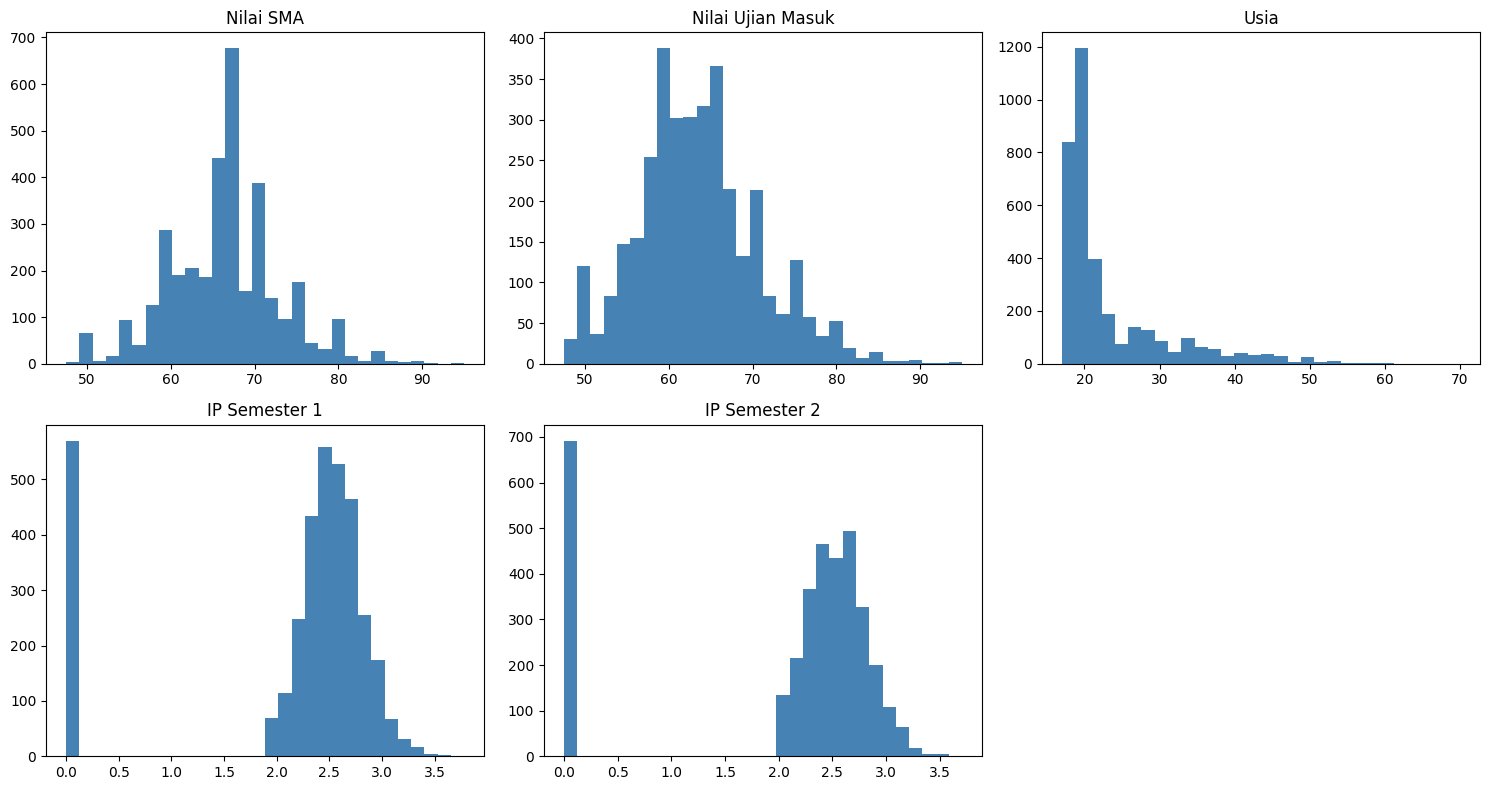

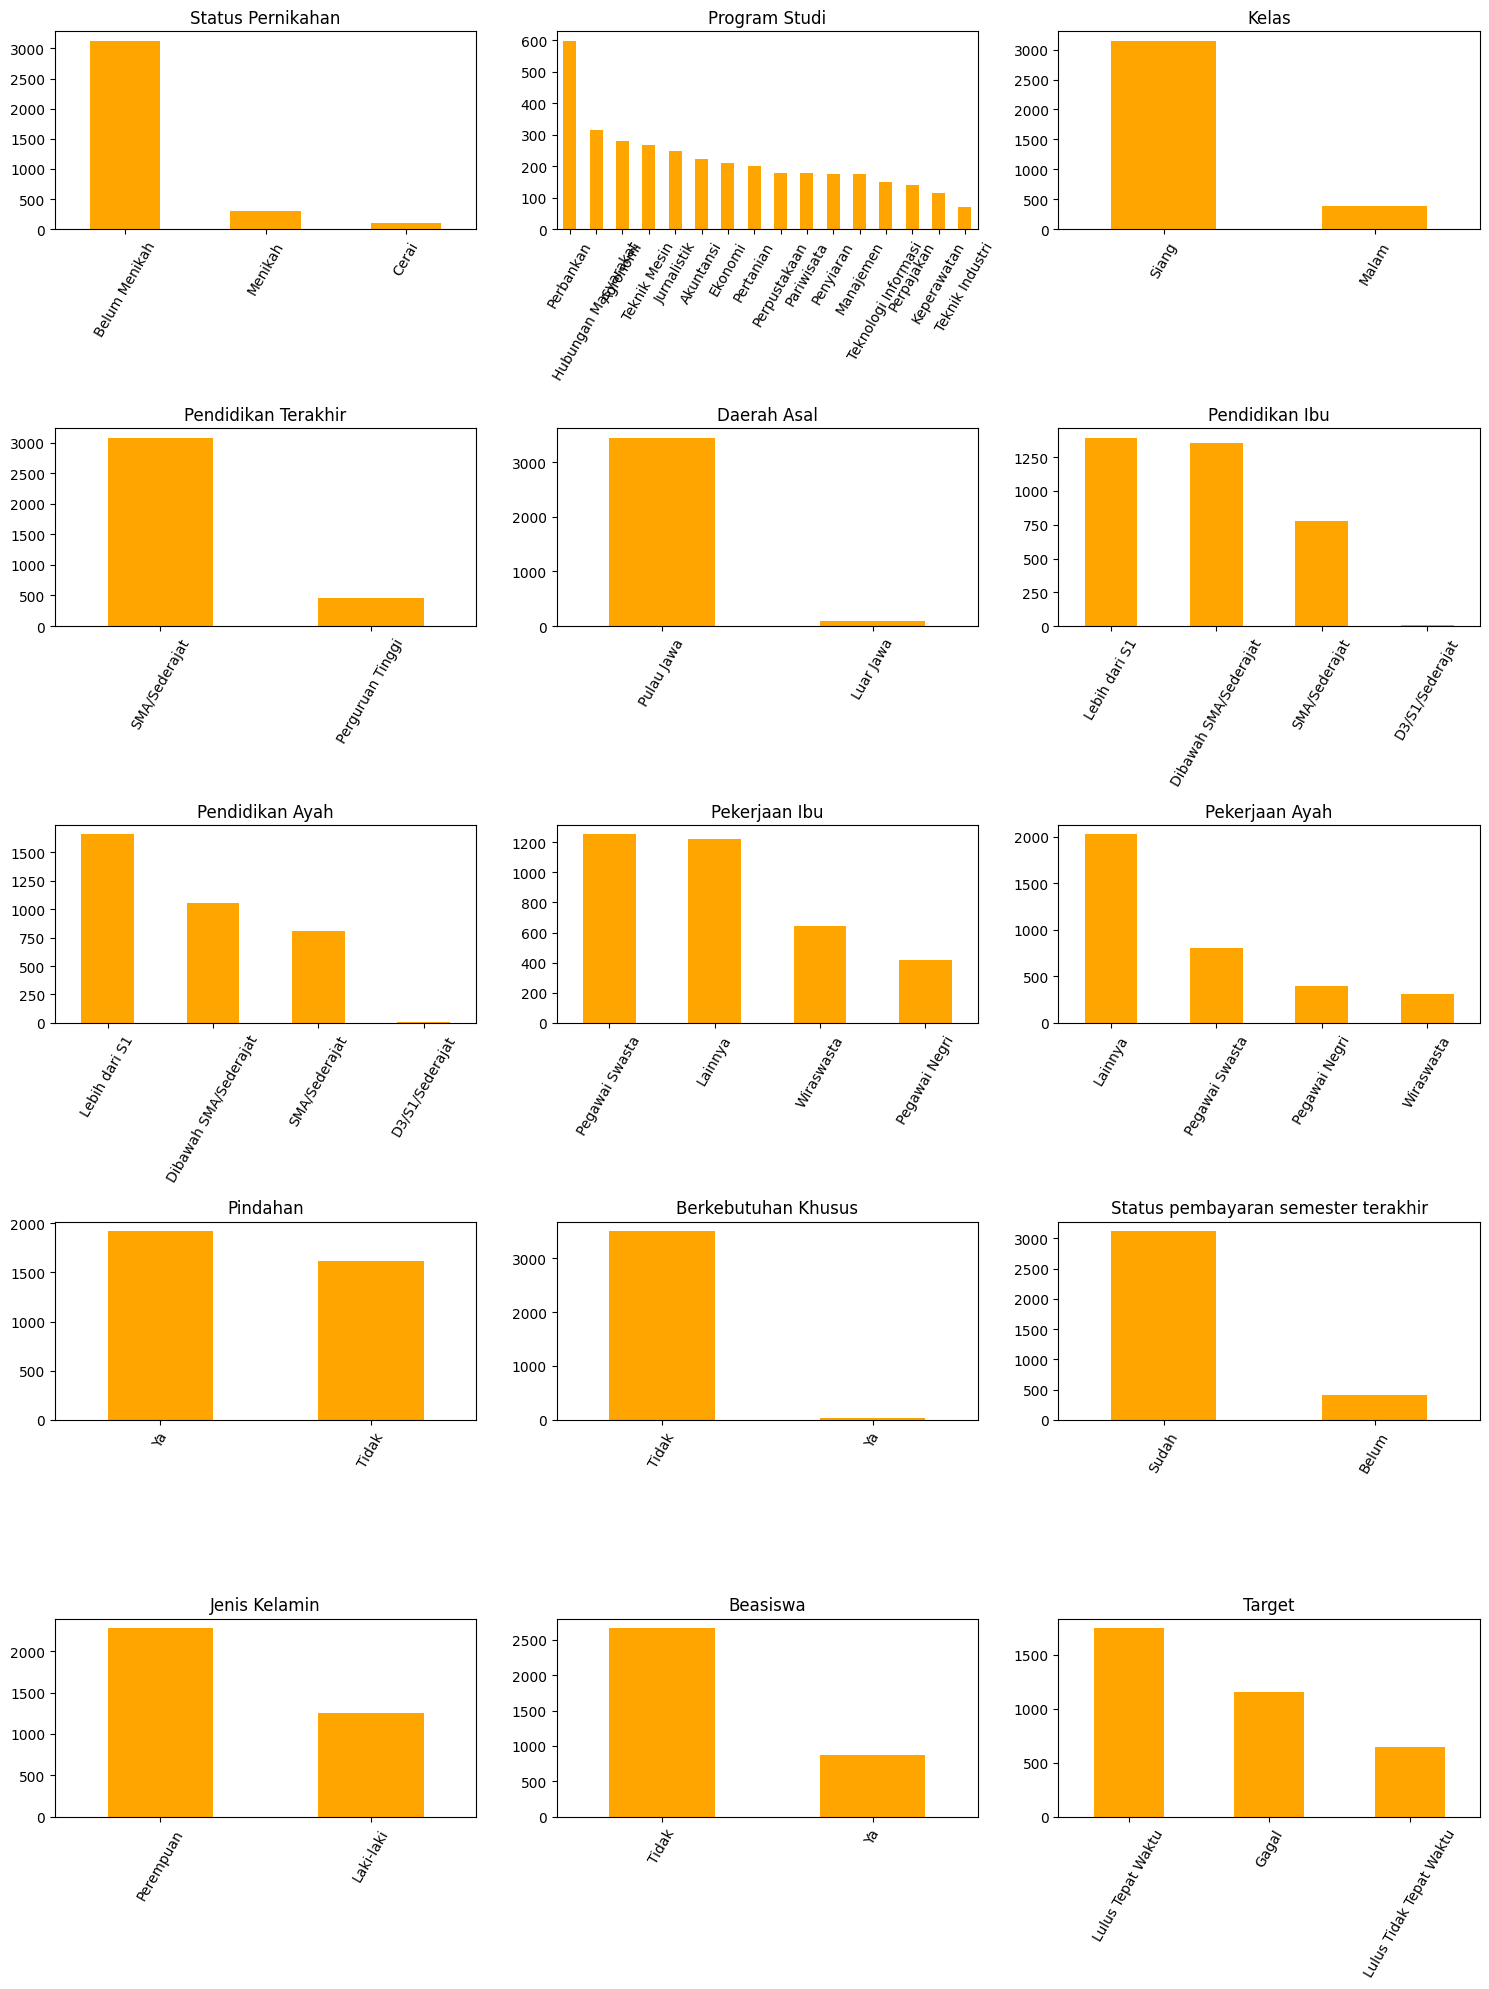

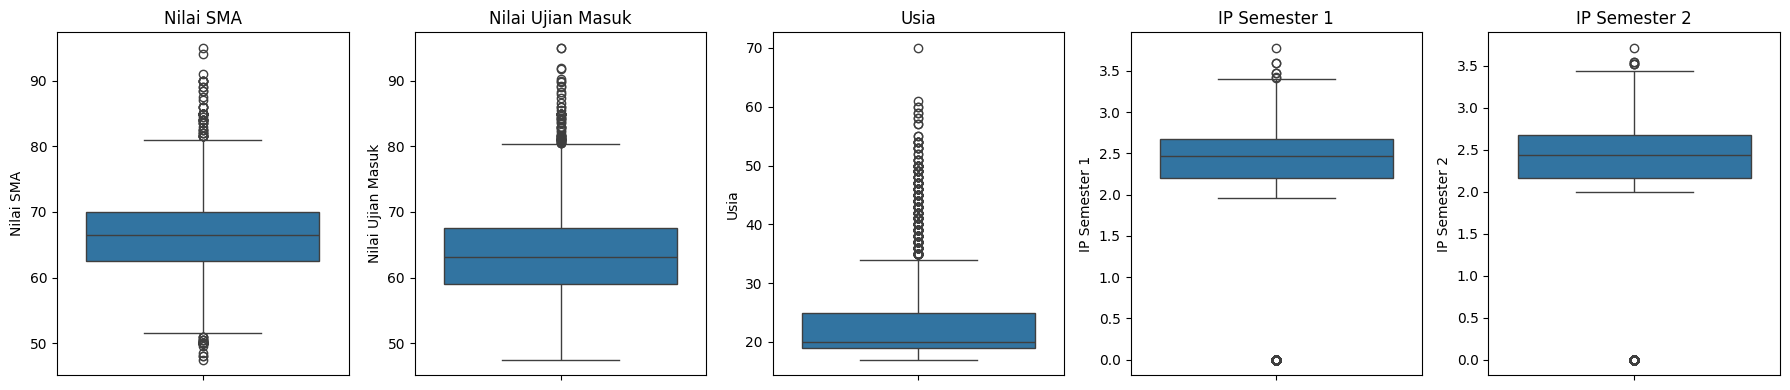

Nilai SMA | batas: 51.25 - 81.25 | outlier: 133
Nilai Ujian Masuk | batas: 46.13 - 80.32 | outlier: 60
Usia | batas: 10.0 - 34.0 | outlier: 350
IP Semester 1 | batas: 1.48 - 3.4 | outlier: 577
IP Semester 2 | batas: 1.39 - 3.45 | outlier: 698
Baris sebelum: 3535 | sesudah: 3328 | dihapus: 207
Target
Lulus Tepat Waktu          1633
Gagal                      1082
Lulus Tidak Tepat Waktu     613
Name: count, dtype: int64


In [18]:
# 1) Menghitung histogram setiap fitur dalam bentuk grafik batang

# Mendaftar kolom numerik
kolom_num = ["Nilai SMA", "Nilai Ujian Masuk", "Usia", "IP Semester 1", "IP Semester 2"]

# Membuat histogram fitur numerik pada kanvas 2 baris x 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()                       # meratakan kotak grafik menjadi satu baris
for i, k in enumerate(kolom_num):
    axes[i].hist(df[k], bins=30, color="steelblue")
    axes[i].set_title(k)
axes[5].axis("off")                       # menyembunyikan kotak ke-6 yang tidak terpakai
plt.tight_layout()
plt.show()

# Membuat grafik batang fitur kategorikal (termasuk Target) pada kanvas 5 baris x 3 kolom
kolom_kat = df.select_dtypes(exclude="number").columns
fig, axes = plt.subplots(5, 3, figsize=(15, 20))
axes = axes.ravel()
for i, k in enumerate(kolom_kat):
    df[k].value_counts().plot(kind="bar", ax=axes[i], color="orange")
    axes[i].set_title(k)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=60)   # memiringkan label agar tidak bertabrakan
plt.tight_layout()
plt.show()

# 2) Mengidentifikasi outlier dengan boxplot
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, k in enumerate(kolom_num):
    sns.boxplot(y=df[k], ax=axes[i])
    axes[i].set_title(k)
plt.tight_layout()
plt.show()

# Menghitung jumlah outlier tiap fitur dengan aturan IQR
for k in kolom_num:
    q1 = df[k].quantile(0.25)        # kuartil 1
    q3 = df[k].quantile(0.75)        # kuartil 3
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah = ((df[k] < batas_bawah) | (df[k] > batas_atas)).sum()
    print(k, "| batas:", round(batas_bawah, 2), "-", round(batas_atas, 2), "| outlier:", jumlah)

# 3) Menghapus outlier dari data
# Outlier dihapus hanya pada Nilai SMA dan Nilai Ujian Masuk.
# IP tidak dihapus karena IP = 0 menandakan mahasiswa gagal, dan Usia tidak dihapus
# karena mahasiswa UT memang banyak yang sudah bekerja (usianya lebih tua).
sebelum = len(df)
for k in ["Nilai SMA", "Nilai Ujian Masuk"]:
    q1 = df[k].quantile(0.25)
    q3 = df[k].quantile(0.75)
    iqr = q3 - q1
    df = df[(df[k] >= q1 - 1.5 * iqr) & (df[k] <= q3 + 1.5 * iqr)]   # menyimpan baris yang bukan outlier

print("Baris sebelum:", sebelum, "| sesudah:", len(df), "| dihapus:", sebelum - len(df))
print(df["Target"].value_counts())

##Task 6
Agar nantinya kita bisa mendapatkan fitur yang relevan, sebaiknya kita melihat hubungan setiap fitur dengan kelas target.

                         Nilai SMA  Nilai Ujian Masuk   Usia  IP Semester 1  \
Target                                                                        
Gagal                        65.41              61.84  25.78           1.47   
Lulus Tidak Tepat Waktu      65.57              62.44  22.01           2.23   
Lulus Tepat Waktu            66.92              63.94  21.52           2.53   

                         IP Semester 2  
Target                                  
Gagal                             1.23  
Lulus Tidak Tepat Waktu           2.22  
Lulus Tepat Waktu                 2.54  


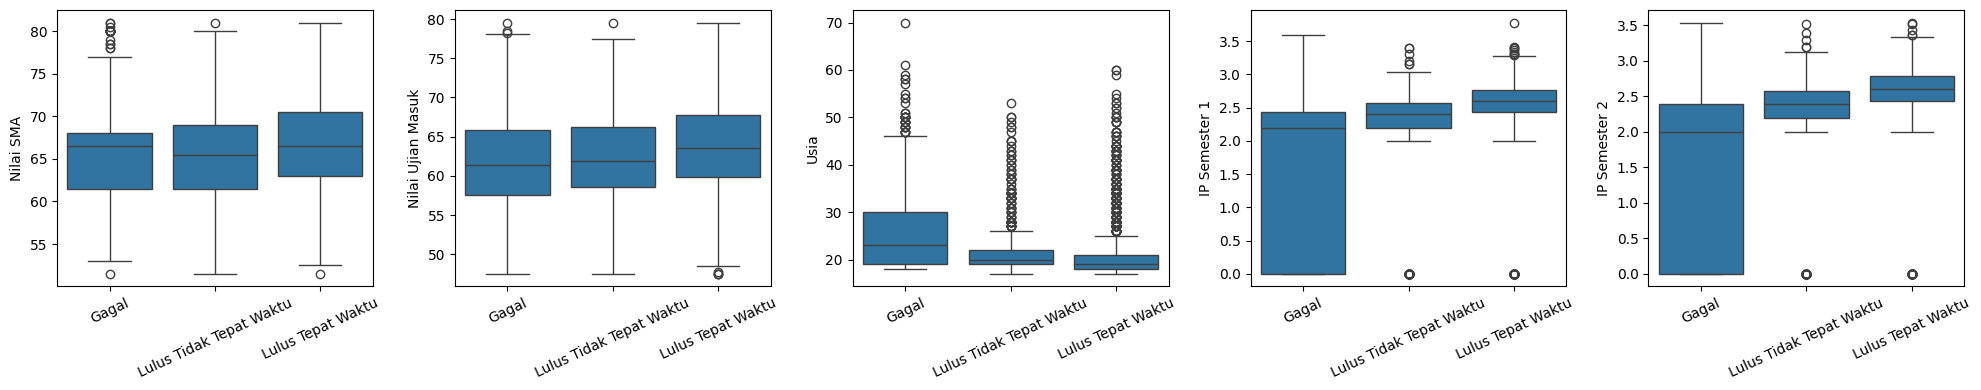

Target                               Gagal  Lulus Tidak Tepat Waktu  \
Status pembayaran semester terakhir                                   
Belum                                 0.88                     0.08   
Sudah                                 0.25                     0.20   

Target                               Lulus Tepat Waktu  
Status pembayaran semester terakhir                     
Belum                                             0.04  
Sudah                                             0.55  
Target    Gagal  Lulus Tidak Tepat Waktu  Lulus Tepat Waktu
Beasiswa                                                   
Tidak      0.39                     0.20               0.41
Ya         0.13                     0.12               0.75


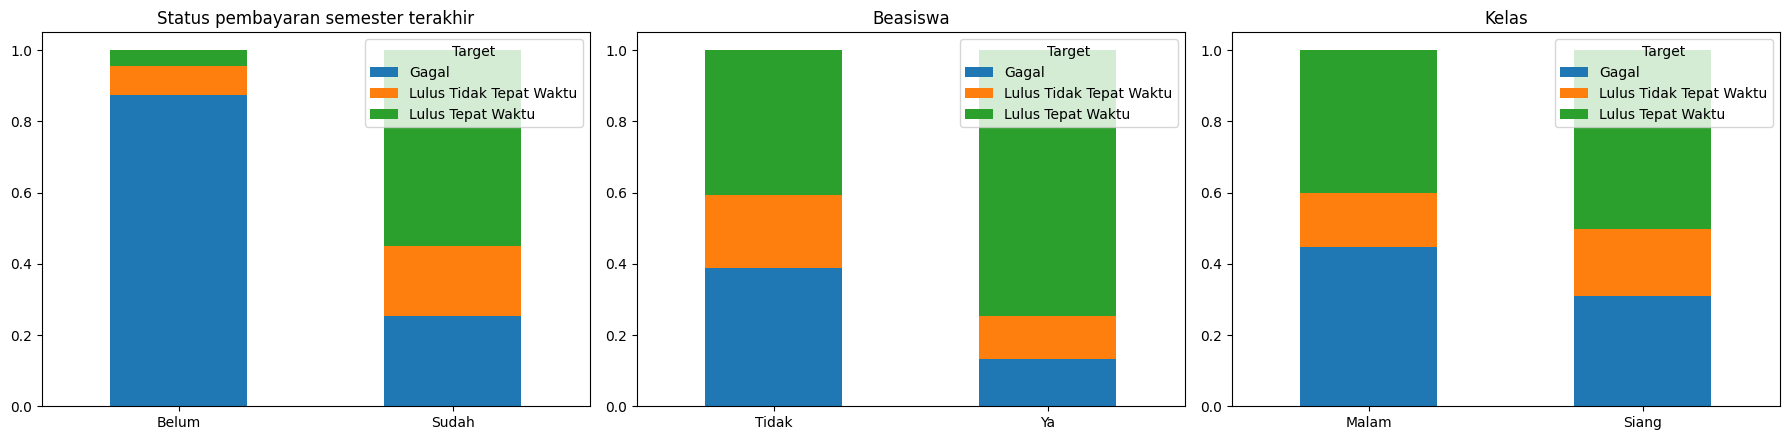

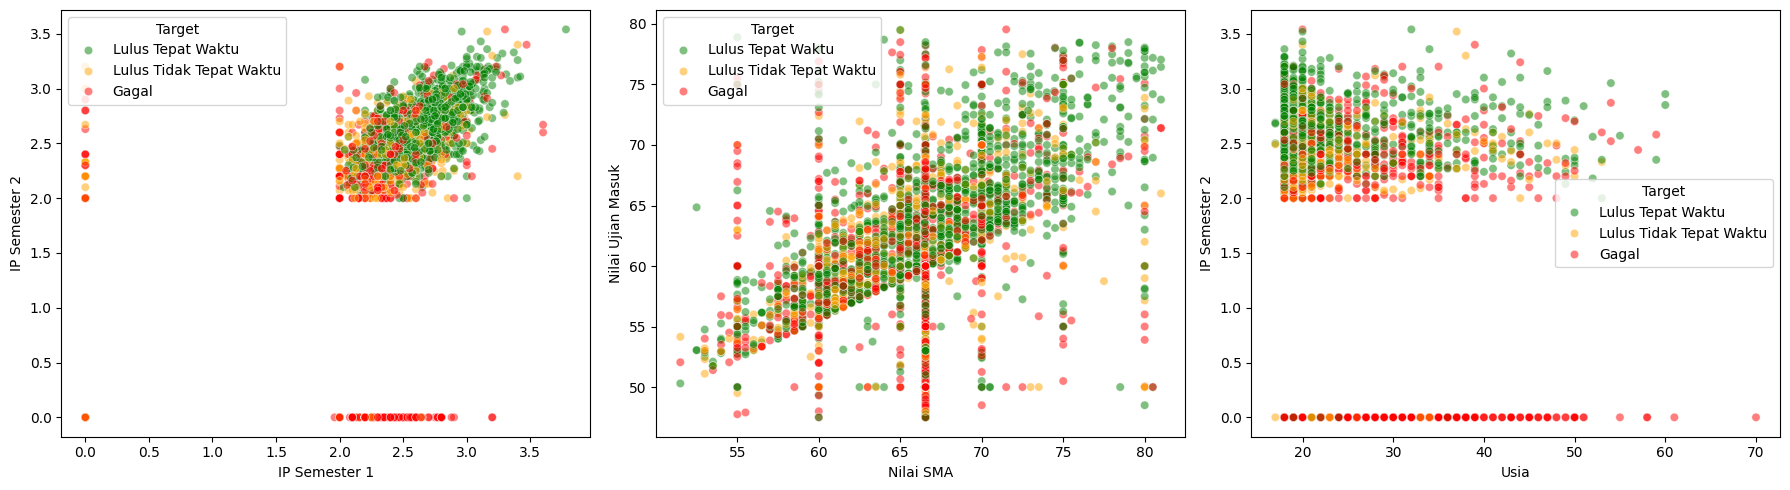

In [19]:
# Mengurutkan kelas Target dari risiko tertinggi ke terendah
urutan_target = ["Gagal", "Lulus Tidak Tepat Waktu", "Lulus Tepat Waktu"]

# 1) Melakukan analisis bivariate (hubungan fitur dengan Target)

# (a) Fitur numerik: menghitung rata-rata tiap fitur pada setiap kelas Target
print(df.groupby("Target")[kolom_num].mean().loc[urutan_target].round(2))

# Menggambar boxplot tiap fitur numerik per kelas Target
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, k in enumerate(kolom_num):
    sns.boxplot(data=df, x="Target", y=k, order=urutan_target, ax=axes[i])
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=25)    # memiringkan label agar terbaca
plt.tight_layout()
plt.show()

# (b) Fitur kategorikal: menghitung proporsi kelas Target pada tiap kategori
print(pd.crosstab(df["Status pembayaran semester terakhir"], df["Target"], normalize="index")[urutan_target].round(2))
print(pd.crosstab(df["Beasiswa"], df["Target"], normalize="index")[urutan_target].round(2))

# Menggambar proporsi Target dalam grafik batang bertumpuk
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for i, k in enumerate(["Status pembayaran semester terakhir", "Beasiswa", "Kelas"]):
    pd.crosstab(df[k], df["Target"], normalize="index")[urutan_target].plot(kind="bar", stacked=True, ax=axes[i])
    axes[i].set_title(k)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# 2) Memplot ke dalam grafik sebaran (scatter), titik diwarnai menurut Target
warna = {"Gagal": "red", "Lulus Tidak Tepat Waktu": "orange", "Lulus Tepat Waktu": "green"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="IP Semester 1", y="IP Semester 2", hue="Target", palette=warna, alpha=0.5, ax=axes[0])
sns.scatterplot(data=df, x="Nilai SMA", y="Nilai Ujian Masuk", hue="Target", palette=warna, alpha=0.5, ax=axes[1])
sns.scatterplot(data=df, x="Usia", y="IP Semester 2", hue="Target", palette=warna, alpha=0.5, ax=axes[2])
plt.tight_layout()
plt.show()

##Task 7
Oke, sepertinya sudah siap, tapi kok jumlah data per-kelas nya tidak seimbang ya, ada beberapa algoritma yang akan terpengaruh dengan kondisi ini, kita akan gunakan algoritma **$\color{orange}{\text{(Random Forest dengan class_weight="balanced")}}$** untuk menyelesaikan masalah ini, jadi kita **$\color{orange}{\text{(tidak akan)}}$** melakukan proses augmentasi data karena **$\color{orange}{\text{(rasio kelas hanya sekitar 2,66 : 1 ,tidak terlalu ekstrem, dan class_weight="balanced" memberi bobot lebih besar pada kelas yang jumlahnya sedikit)}}$**

In [20]:
# 1) Augmentasi data untuk balancing kelas (opsional)
# Augmentasi tidak dilakukan, jadi di sini hanya memeriksa keseimbangan kelas Target

dist = df["Target"].value_counts()      # menghitung jumlah mahasiswa tiap kelas
print(dist)

# Menghitung proporsi tiap kelas dalam persen
print((dist / dist.sum() * 100).round(1))

# Menghitung rasio kelas terbesar dibanding kelas terkecil
print("Rasio terbesar : terkecil =", round(dist.max() / dist.min(), 2), ": 1")

Target
Lulus Tepat Waktu          1633
Gagal                      1082
Lulus Tidak Tepat Waktu     613
Name: count, dtype: int64
Target
Lulus Tepat Waktu          49.1
Gagal                      32.5
Lulus Tidak Tepat Waktu    18.4
Name: count, dtype: float64
Rasio terbesar : terkecil = 2.66 : 1


Selanjutnya datanya perlu kita bagi dengan ratio **$\color{orange}{\text{(80)}}$** : **$\color{orange}{\text{(20)}}$**
Dimana **$\color{orange}{\text{(80)}}$** adalah data training
Dan **$\color{orange}{\text{(20)}}$** adalah data testing


In [21]:
# Persiapan fitur

y = df["Target"]                              # y = kelas yang ingin diprediksi
X = df.drop(columns=["ID", "Target"])         # X = fitur (ID dibuang karena hanya penanda)

# Mengubah kolom teks menjadi angka (One-Hot Encoding), karena algoritma hanya membaca angka
X = pd.get_dummies(X, drop_first=True)
print("Bentuk fitur akhir:", X.shape)

# 1) Melakukan pembagian data training dan testing
from sklearn.model_selection import train_test_split

# Membagi data 80% training dan 20% testing
# stratify=y menjaga proporsi kelas tetap sama, random_state=42 mengunci acakan
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Data training:", X_train.shape, "| Data testing:", X_test.shape)

# Memeriksa proporsi kelas pada data training dan testing
print(y_train.value_counts(normalize=True).sort_index().round(3))
print(y_test.value_counts(normalize=True).sort_index().round(3))

Bentuk fitur akhir: (3328, 42)
Data training: (2662, 42) | Data testing: (666, 42)
Target
Gagal                      0.325
Lulus Tepat Waktu          0.491
Lulus Tidak Tepat Waktu    0.184
Name: proportion, dtype: float64
Target
Gagal                      0.324
Lulus Tepat Waktu          0.491
Lulus Tidak Tepat Waktu    0.185
Name: proportion, dtype: float64


##Task 8
Sekarang kita mulai training nya

In [22]:
# 1) Melakukan proses training dengan algoritma yang telah dipilih (Random Forest)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Membuat model Random Forest
# class_weight="balanced": kelas yang jumlahnya sedikit diberi bobot lebih besar
# max_depth dan min_samples_leaf: membatasi kerumitan pohon agar tidak overfitting
model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5,
                               class_weight="balanced", random_state=42)

# Melatih model dengan data training
model.fit(X_train, y_train)

# Menghitung akurasi pada data training dan data testing
print("Akurasi training:", round(accuracy_score(y_train, model.predict(X_train)), 3))
print("Akurasi testing :", round(accuracy_score(y_test, model.predict(X_test)), 3))

# 2) Melakukan evaluasi model dengan K-fold
from sklearn.model_selection import cross_val_score

# Membagi data training menjadi 5 bagian (5-fold), tiap bagian bergantian menjadi data uji
scores = cross_val_score(model, X_train, y_train, cv=5)
print("Akurasi tiap fold:", scores.round(3))
print("Rata-rata        :", round(scores.mean(), 3))

Akurasi training: 0.75
Akurasi testing : 0.685
Akurasi tiap fold: [0.689 0.649 0.697 0.694 0.658]
Rata-rata        : 0.677


#Task 9
Training sudah selesai dan model sudah diketahui, kita uji hasilnya dengan data testing untuk melihat kemungkinan overfitting dan underfitting, sekaligus menghitung kualitas model dengan matrik pengukuran

Akurasi training: 0.75
Akurasi testing : 0.685
                         precision    recall  f1-score   support

                  Gagal       0.77      0.70      0.73       216
      Lulus Tepat Waktu       0.79      0.78      0.79       327
Lulus Tidak Tepat Waktu       0.34      0.41      0.37       123

               accuracy                           0.68       666
              macro avg       0.63      0.63      0.63       666
           weighted avg       0.70      0.68      0.69       666



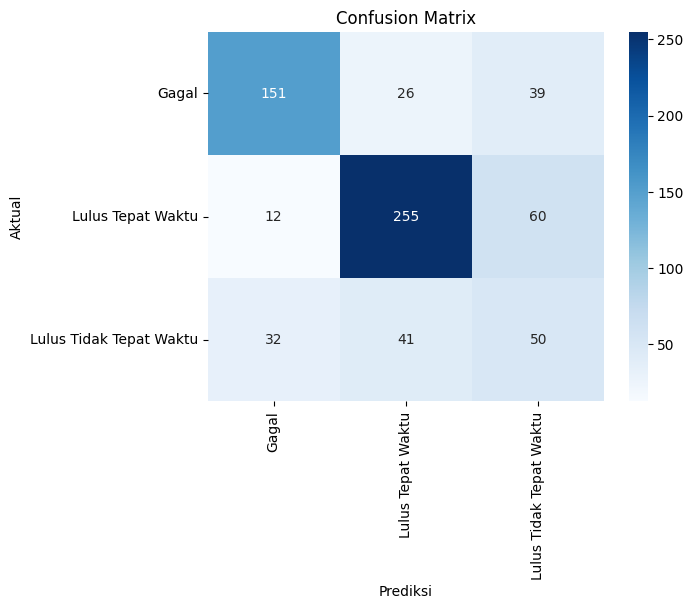

In [23]:
# 1) Evaluasi dengan data testing
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)      # model menebak kelas data testing

# Membandingkan akurasi training dan testing untuk melihat overfitting/underfitting
print("Akurasi training:", round(accuracy_score(y_train, model.predict(X_train)), 3))
print("Akurasi testing :", round(accuracy_score(y_test, y_pred), 3))

# 2) Menghitung kualitas model dengan matrik pengukuran
# Menampilkan precision, recall, dan f1-score tiap kelas
print(classification_report(y_test, y_pred))

# Menghitung confusion matrix, lalu menggambarnya sebagai heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix")
plt.show()

##Task 10
Berdasarkan hasil evaluasi, kita bisa menyimpulkan bahwa



1.  Akurasi model cukup baik dan konsisten. Model Random Forest mencapai akurasi 68,5% pada data testing. Hasil K-fold (rata-rata 67,7%) hampir sama, sehingga model stabil.
2.  Model tidak overfitting maupun underfitting. Akurasi training 75% dan testing 68,5%, selisihnya hanya sekitar 6,5 poin. Akurasi ini juga jauh di atas tebakan kelas terbanyak (49,1%).
3.   Kelas Gagal dikenali dengan cukup baik, dengan precision 0,77 dan recall 0,70. Dari 216 mahasiswa yang aslinya gagal, 151 berhasil dikenali. Kelas Lulus Tepat Waktu paling baik (F1 0,79). Kelas Lulus Tidak Tepat Waktu paling lemah (F1 0,37) karena karakteristiknya berada di antara dua kelas lain, sehingga banyak tertukar (60 ditebak Lulus Tepat Waktu dan 32 ditebak Gagal).
4.   Faktor yang berkaitan dengan kegagalan berdasarkan analisis Task 6 adalah IP semester 1 dan 2 yang rendah (terutama bernilai 0), belum membayar biaya semester, tidak menerima beasiswa, dan usia yang lebih tinggi.
5.   Manfaat dan saran. Model cukup layak sebagai peringatan dini untuk mendeteksi mahasiswa berisiko gagal, sehingga wali akademik bisa memberi konseling lebih awal. Namun prediksi kelas Lulus Tidak Tepat Waktu belum andal, jadi hasilnya dipakai sebagai petunjuk, bukan keputusan akhir. Model bisa ditingkatkan dengan mencoba algoritma lain atau menambah fitur.







